In [1]:
# 1. Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import pickle

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

In [2]:
# 2. Load the cleaned data (output of the EDA and cleaning notebook)
df = pd.read_csv("Mumbai_House_Prices_Cleaned.csv")
print(df.shape)
df.head()

(53215, 9)


,bhk,type,locality,area,region,status,age,price_lakhs,price_per_sqft
0,2,Apartment,Radheya Sai Enclave Building No 2,640,Naigaon East,Under Construction,New,52.51,8204.687500
1,2,Apartment,Romell Serene,610,Borivali West,Under Construction,New,173.00,28360.655738
2,2,Apartment,Soundlines Codename Urban Rainforest,876,Panvel,Under Construction,New,59.98,6847.031963
3,2,Apartment,Origin Oriana,659,Mira Road East,Under Construction,New,94.11,14280.728376
4,5,Villa,Agami Estancia,2921,Boisar,Under Construction,New,199.00,6812.735365


In [3]:
# 3. Check for missing values
print(df.isnull().sum())

bhk               0
type              0
locality          0
area              0
region            0
status            0
age               0
price_lakhs       0
price_per_sqft    0
dtype: int64


In [4]:
# 4. Choose the target and the features
# Target: price_lakhs
# price_per_sqft is left out because it is calculated from the price (it would leak the answer)
target = "price_lakhs"
features = ["bhk", "type", "region", "area", "status", "age"]

X = df[features]
y = df[target]

In [5]:
# 5. Convert text columns to numbers (one-hot encoding)
X = pd.get_dummies(X, columns=["type", "region", "status", "age"], drop_first=True)
print(X.shape)
X.head()

(53215, 227)


,bhk,area,type_Independent House,type_Penthouse,type_Studio Apartment,type_Villa,region_Agripada,region_Airoli,region_Ambarnath,region_Ambernath East,...,region_Warai,region_Worli,region_kandivali,region_kasaradavali thane west,region_mumbai,region_sector,region_vile parle west,status_Under Construction,age_Resale,age_Unknown
0,2,640,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
1,2,610,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
2,2,876,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
3,2,659,False,False,False,False,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False
4,5,2921,False,False,False,True,False,False,False,False,...,False,False,False,False,False,False,False,True,False,False


In [6]:
# 6. Split into train and test sets (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (42572, 227)
Test: (10643, 227)


In [7]:
# 7. A helper function to check a model
def evaluate(name, model):
    pred = model.predict(X_test)
    r2 = r2_score(y_test, pred)
    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    print(name)
    print("R2 score:", round(r2, 3))
    print("MAE (Lakhs):", round(mae, 2))
    print("RMSE (Lakhs):", round(rmse, 2))
    print()
    return r2

In [8]:
# 8. Model 1: Linear Regression
lr = LinearRegression()
lr.fit(X_train, y_train)
lr_score = evaluate("Linear Regression", lr)

Linear Regression
R2 score: 0.805
MAE (Lakhs): 31.85
RMSE (Lakhs): 47.05



In [9]:
# 9. Model 2: Decision Tree
dt = DecisionTreeRegressor(max_depth=12, random_state=42)
dt.fit(X_train, y_train)
dt_score = evaluate("Decision Tree", dt)

Decision Tree
R2 score: 0.732
MAE (Lakhs): 35.28
RMSE (Lakhs): 55.19



In [10]:
# 10. Model 3: Random Forest
rf = RandomForestRegressor(n_estimators=100, min_samples_leaf=2, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)
rf_score = evaluate("Random Forest", rf)

Random Forest
R2 score: 0.858
MAE (Lakhs): 21.88
RMSE (Lakhs): 40.15



               Model  R2 score
0  Linear Regression  0.805298
1      Decision Tree  0.732096
2      Random Forest  0.858192


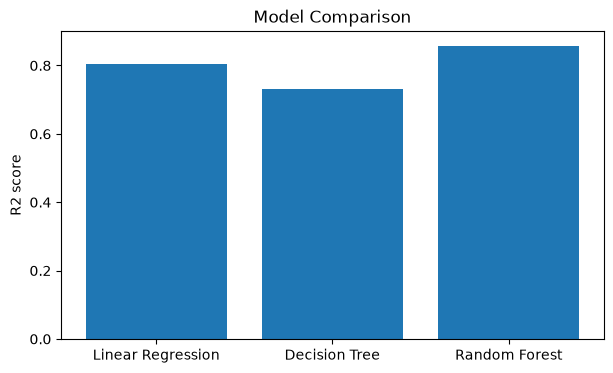

In [11]:
# 11. Compare the models
results = pd.DataFrame({
    "Model": ["Linear Regression", "Decision Tree", "Random Forest"],
    "R2 score": [lr_score, dt_score, rf_score]
})
print(results)

plt.figure(figsize=(7, 4))
plt.bar(results["Model"], results["R2 score"])
plt.ylabel("R2 score")
plt.title("Model Comparison")
plt.show()

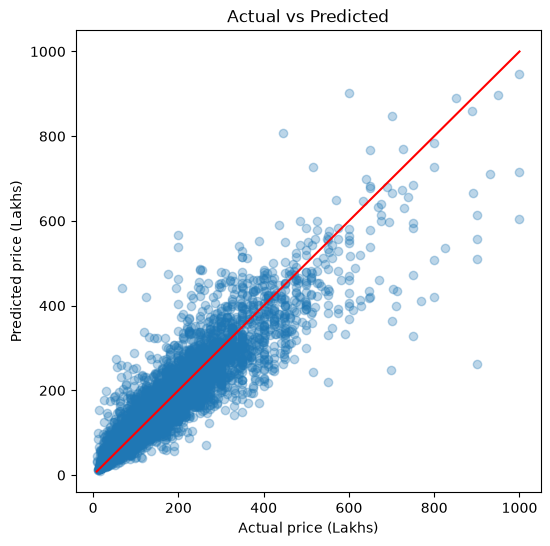

In [12]:
# 12. Actual vs predicted prices for the best model (Random Forest)
pred = rf.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred, alpha=0.3)
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="red")
plt.xlabel("Actual price (Lakhs)")
plt.ylabel("Predicted price (Lakhs)")
plt.title("Actual vs Predicted")
plt.show()

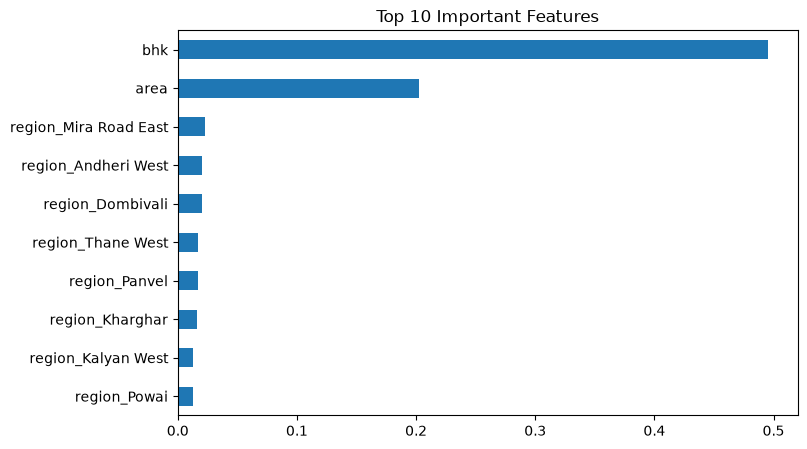

In [13]:
# 13. Most important features
importance = pd.Series(rf.feature_importances_, index=X.columns)
importance.sort_values(ascending=False).head(10).plot(kind="barh", figsize=(8, 5))
plt.gca().invert_yaxis()
plt.title("Top 10 Important Features")
plt.show()

In [14]:
# 14. Check for overfitting (train score vs test score)
print("Random Forest train R2:", round(rf.score(X_train, y_train), 3))
print("Random Forest test R2:", round(rf.score(X_test, y_test), 3))

Random Forest train R2: 0.938
Random Forest test R2: 0.858


In [15]:
# 15. Predict the price of a new house
def predict_price(bhk, area, house_type, region, status, age):
    # start with a row of zeros for every column the model knows
    row = pd.DataFrame(0, index=[0], columns=X.columns)
    row["bhk"] = bhk
    row["area"] = area

    # switch on the matching one-hot columns (if they exist)
    for col in ["type_" + house_type, "region_" + region, "status_" + status, "age_" + age]:
        if col in row.columns:
            row[col] = 1

    price = rf.predict(row)[0]
    return price

price = predict_price(2, 850, "Apartment", "Andheri West", "Ready to move", "Resale")
print("Predicted price (Lakhs):", round(price, 2))

Predicted price (Lakhs): 243.67


In [16]:
# 16. Save the model and the column names
pickle.dump(rf, open("house_price_model.pkl", "wb"))
pickle.dump(list(X.columns), open("model_columns.pkl", "wb"))
print("Model saved")

Model saved
